# Market Basket Analysis Using Association Rule Mining

**A College Minor Project**

| | |
|---|---|
| **Student name** | _[Your Name]_ |
| **Roll number** | _[Your Roll Number]_ |
| **College** | _[Your College Name]_ |
| **Department** | _[Department Name]_ |
| **Guide** | _[Guide Name]_ |
| **Academic year** | _[2025-26]_ |

---

## Abstract

Retail stores record thousands of shopping baskets every day. Some products are bought together far more
often than chance would suggest. This project uses **market basket analysis** and the **Apriori algorithm**
to discover those product combinations in the public **Groceries** dataset. Each row of the dataset is one
shopping basket. The notebook cleans the baskets, converts them into a one-hot encoded table, finds frequent
itemsets at a **1% minimum support** threshold, and generates association rules with **confidence >= 40%**
and **lift > 1**. The strongest rules are visualised and translated into practical suggestions for product
placement, bundles, and recommendations.

> **Important:** Every number reported below is calculated from the dataset when this notebook runs.
> No result is typed in by hand. Re-running the notebook reproduces the same analysis because a fixed
> random seed is set (no random sampling is actually needed for this project).

---

## How to use this notebook

1. Install the packages from `requirements.txt`.
2. Put the dataset at `data/groceries.csv` (download link in the next section).
3. Open this notebook and choose **Kernel -> Restart & Run All**.
4. If the dataset is missing, the notebook automatically switches to a small built-in sample so that
   every cell still runs. The sample is only a backup; conclusions in the report use the full dataset.

**Contents**

1. Introduction and objectives
2. Setup
3. Load the data
4. Explore and clean the baskets
5. Most frequently purchased products
6. Convert baskets to a one-hot table
7. Apriori: find frequent itemsets
8. Generate and rank association rules
9. What support, confidence, and lift mean
10. Visualisations
11. Interpretation and retail recommendations
12. Limitations
13. Conclusion and future scope
14. References

## 1. Introduction and objectives

### What is data mining?

Data mining is the process of discovering useful patterns in large collections of data. A supermarket does
not usually need a complicated prediction model; it needs simple, explainable patterns such as
*"customers who buy soup often buy bread."* Those patterns can guide shelf layout, offers, and
recommendations.

### What is market basket analysis?

Market basket analysis looks for products that appear together in the same shopping basket. It is also
called **affinity analysis**. The classic example is the (often repeated, rarely verified) story of
beer and nappies. The important idea is not the story: it is that co-occurrence can be measured with three
numbers — **support**, **confidence**, and **lift**.

### Problem statement

Given a file of shopping baskets, which products are purchased together more often than expected by
chance, and which of those combinations are strong enough to be useful to a retailer?

### Objectives

1. Load and clean a public grocery transaction dataset.
2. Describe the data (number of transactions, products, and basket sizes).
3. Identify the most frequently purchased products.
4. Convert baskets into the one-hot format required by Apriori.
5. Mine frequent itemsets at a clearly justified minimum support.
6. Generate association rules using confidence and lift.
7. Rank the rules and explain the strongest ones in plain language.
8. Visualise product frequency, rule quality, and the strongest rules.
9. Discuss practical retail uses, limitations, and future improvements.

### Scope

The project studies **co-occurrence only**. It does not use prices, profit margins, customer identities,
loyalty history, or store layout. It is an educational analysis of one public dataset, not a production
recommendation engine.

## 2. Setup

The next cell imports the libraries and creates the output folders. A fixed random seed is set for
reproducibility. No random sampling is required for the main analysis, but the seed is kept so that any
future extension behaves consistently.

**Libraries used**

- **pandas / NumPy** — tabular data and numerical work.
- **mlxtend** — `TransactionEncoder`, `apriori`, and `association_rules`.
- **Matplotlib / Seaborn** — charts.
- **Counter** — counting how often each product occurs.

In [1]:
import warnings
from collections import Counter
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------------
# Reproducibility and project folders
# ---------------------------------------------------------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"
IMAGES_DIR = BASE_DIR / "images"
for folder in (DATA_DIR, RESULTS_DIR, IMAGES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "groceries.csv"
SAMPLE_PATH = DATA_DIR / "sample_baskets.csv"

# Chart style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 180
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.autolayout"] = True

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
import mlxtend
print("mlxtend:", mlxtend.__version__)
print("Project folder:", BASE_DIR)

pandas : 3.1.0
numpy  : 2.5.4
mlxtend: 0.25.0
Project folder: C:\Users\SHINGADE27R\Documents\Default Project\market-basket-analysis


## 3. Load the data

### Dataset source

The project uses the **Groceries** dataset, a well-known public transaction dataset distributed with the
R package `arules` and mirrored in the *Machine Learning with R* repository on GitHub.

- **Download link:** <https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv>
- **Save as:** `data/groceries.csv`
- **Format:** one shopping basket per line; product names separated by commas.
- **Size:** 9,835 transactions and 169 distinct products (verified when the cell below runs).

The dataset describes baskets from a grocery store. It is an **older snapshot**: it has no date, price,
quantity, customer ID, or store location. Those missing details matter when interpreting the results.

The cell below loads the CSV as raw text instead of using `read_csv`, because each line has a variable
number of comma-separated products (there is no fixed number of columns). If the file is missing, a small
hand-written sample is used and a warning is printed.

In [2]:
# A small backup sample, used only when data/groceries.csv is absent.
SAMPLE_BASKETS = [
    ["whole milk", "bread", "butter", "eggs"],
    ["whole milk", "yogurt", "berries"],
    ["root vegetables", "onions", "other vegetables", "rice"],
    ["whole milk", "bread", "eggs", "butter"],
    ["pasta", "tomato sauce", "cheese"],
    ["whole milk", "yogurt", "whole milk", "berries"],
    ["root vegetables", "other vegetables", "onions"],
    ["chips", "soda", "salsa"],
    ["coffee", "whole milk", "sugar"],
    ["bread", "butter", "jam"],
    ["whole milk", "cereal", "bananas"],
    ["root vegetables", "other vegetables", "tomatoes"],
    ["pasta", "cheese", "tomato sauce", "olive oil"],
    ["yogurt", "whole milk", "berries"],
    ["eggs", "bread", "whole milk"],
    ["chips", "soda", "beer"],
    ["whole milk", "butter", "bread", "eggs"],
    ["onions", "root vegetables", "other vegetables", "rice"],
    ["coffee", "sugar", "whole milk"],
    ["pasta", "tomato sauce", "cheese", "bread"],
    ["whole milk", "yogurt", "bananas"],
    ["root vegetables", "other vegetables", "onions", "tomatoes"],
    ["bread", "eggs", "butter", "jam"],
    ["chips", "salsa", "soda"],
    ["whole milk", "cereal", "bananas"],
    ["pasta", "cheese", "tomato sauce"],
    ["yogurt", "berries", "whole milk"],
    ["root vegetables", "onions", "rice"],
    ["coffee", "whole milk", "sugar"],
    ["bread", "butter", "whole milk"],
    ["eggs", "whole milk", "yogurt"],
    ["pasta", "tomato sauce", "cheese", "olive oil"],
    ["chips", "soda"],
    ["root vegetables", "other vegetables", "onions", "tomatoes"],
    ["whole milk", "bread", "eggs", "butter", "jam"],
    ["yogurt", "whole milk", "berries", "bananas"],
    ["coffee", "sugar", "bread"],
    ["pasta", "cheese", "tomato sauce", "bread"],
    ["onions", "root vegetables", "other vegetables"],
    ["whole milk", "cereal", "whole milk", "bananas"],
]

USING_SAMPLE = not DATA_PATH.exists()

if USING_SAMPLE:
    print("WARNING: data/groceries.csv was not found.")
    print("Using the small built-in sample so the notebook can still run.")
    print("Download the full dataset for the results reported in the project report:")
    print("https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv")
    raw_lines = [",".join(basket) for basket in SAMPLE_BASKETS]
    # Save the sample for inspection / reuse.
    SAMPLE_PATH.write_text("\n".join(raw_lines), encoding="utf-8")
    print(f"\nSample saved to: {SAMPLE_PATH}")
else:
    with open(DATA_PATH, "r", encoding="utf-8") as file:
        raw_lines = file.read().splitlines()
    print(f"Loaded: {DATA_PATH}")

print(f"Raw lines read: {len(raw_lines):,}")
print("\nFirst five raw lines:")
for line in raw_lines[:5]:
    print("  ", line)

Loaded: C:\Users\SHINGADE27R\Documents\Default Project\market-basket-analysis\data\groceries.csv
Raw lines read: 9,835

First five raw lines:
   citrus fruit,semi-finished bread,margarine,ready soups
   tropical fruit,yogurt,coffee
   whole milk
   pip fruit,yogurt,cream cheese ,meat spreads
   other vegetables,whole milk,condensed milk,long life bakery product


## 4. Explore and clean the baskets

The raw file is almost clean, but a real project must still check for problems. The cleaning steps are:

1. **Read each line as one basket.** A line is one shopping transaction.
2. **Strip whitespace** around every product name.
3. **Convert names to lowercase** so that `Milk` and `milk` are not treated as two products.
4. **Remove empty tokens** (for example, a trailing comma produces an empty string).
5. **Remove missing-like values** such as `nan` or `none`.
6. **Remove duplicate products inside one basket.** Two rows of the same product in one basket do not
   change "was this product bought?" and would distort the one-hot table.
7. **Drop completely empty baskets.**

One deliberate decision: **single-item baskets are kept.** They are valid purchases and they count in the
denominator when support is calculated. They cannot form a pair themselves, but removing them would
artificially inflate the support of every product pair. The cleaning report below shows exactly what was
removed.

In [3]:
raw_row_count = len(raw_lines)
missing_tokens = 0
empty_rows_removed = 0
duplicate_items_removed = 0
baskets = []

for line in raw_lines:
    # Split one transaction into product names.
    tokens = [str(item).strip().lower() for item in line.split(",")]

    cleaned_tokens = []
    for token in tokens:
        if token == "":
            continue
        if token in {"nan", "none", "null"}:
            missing_tokens += 1
            continue
        cleaned_tokens.append(token)

    if not cleaned_tokens:
        empty_rows_removed += 1
        continue

    # dict.fromkeys keeps the first occurrence and preserves order.
    before = len(cleaned_tokens)
    unique_tokens = list(dict.fromkeys(cleaned_tokens))
    duplicate_items_removed += before - len(unique_tokens)
    baskets.append(unique_tokens)

basket_sizes = pd.Series([len(basket) for basket in baskets], name="items_per_basket")
single_item_baskets = int((basket_sizes == 1).sum())
unique_products = len({item for basket in baskets for item in basket})

cleaning_report = pd.DataFrame(
    {
        "Check": [
            "Raw lines / transactions read",
            "Empty or invalid rows removed",
            "Missing-like product tokens removed",
            "Duplicate products removed inside baskets",
            "Valid transactions kept",
            "Distinct products",
            "Average basket size",
            "Median basket size",
            "Largest basket",
            "Single-item baskets kept",
        ],
        "Value": [
            f"{raw_row_count:,}",
            f"{empty_rows_removed:,}",
            f"{missing_tokens:,}",
            f"{duplicate_items_removed:,}",
            f"{len(baskets):,}",
            f"{unique_products:,}",
            f"{basket_sizes.mean():.2f}",
            f"{basket_sizes.median():.0f}",
            f"{basket_sizes.max():,}",
            f"{single_item_baskets:,}",
        ],
    }
)

display(cleaning_report)
print(f"\nKept {len(baskets):,} valid baskets with {unique_products} distinct products.")
print(
    f"{single_item_baskets:,} baskets ({single_item_baskets / len(baskets):.1%}) contain only one item. "
    "They stay in the analysis because they are real purchases and affect support."
)

,Check,Value
0,Raw lines / transactions read,"9,835"
1,Empty or invalid rows removed,0
2,Missing-like product tokens removed,0
3,Duplicate products removed inside baskets,0
4,Valid transactions kept,"9,835"
5,Distinct products,169
6,Average basket size,4.41
7,Median basket size,3
8,Largest basket,32
9,Single-item baskets kept,"2,159"



Kept 9,835 valid baskets with 169 distinct products.
2,159 baskets (22.0%) contain only one item. They stay in the analysis because they are real purchases and affect support.


### Dataset at a glance

The table above is the dataset description requested in the project brief. On the full Groceries file you
should see **9,835 transactions**, **169 products**, and an average basket of about **4.4 items**. The
median basket has only 3 items, while the largest has 32 — grocery shopping is dominated by small trips.

The next cell adds a simple distribution of basket sizes. This is useful context: if most baskets are very
small, pairs will naturally have low support.

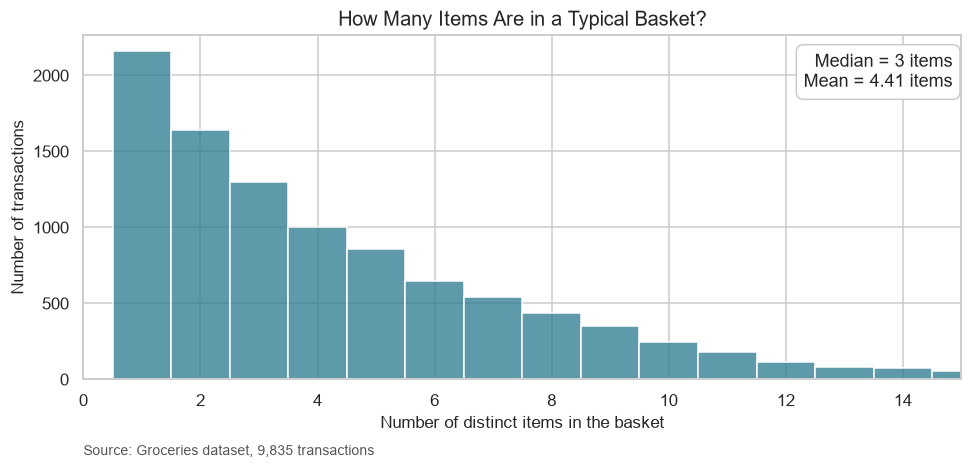

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(basket_sizes, bins=range(1, int(basket_sizes.max()) + 2), discrete=True,
             color="#2a788e", ax=ax)
ax.set_title("How Many Items Are in a Typical Basket?")
ax.set_xlabel("Number of distinct items in the basket")
ax.set_ylabel("Number of transactions")
ax.set_xlim(0, 15)
ax.text(0.99, 0.95, f"Median = {basket_sizes.median():.0f} items\nMean = {basket_sizes.mean():.2f} items",
        transform=ax.transAxes, ha="right", va="top",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#cccccc"))
ax.text(0.0, -0.22, f"Source: Groceries dataset, {len(baskets):,} transactions",
        transform=ax.transAxes, fontsize=9, color="#555555")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "01_basket_sizes.png", bbox_inches="tight")
plt.show()

## 5. Most frequently purchased products

The frequency of a product is simply the number of baskets that contain it. Dividing by the number of
transactions gives its **support**. For example, if whole milk appears in 2,513 of 9,835 baskets, its
support is about 25.6%.

This is descriptive, not yet association rule mining. It answers "what sells often?", while the later
rules answer "what sells *together*?".

In [5]:
item_counter = Counter(item for basket in baskets for item in basket)
product_counts = (
    pd.DataFrame(
        {
            "product": list(item_counter.keys()),
            "baskets": list(item_counter.values()),
        }
    )
    .assign(support_pct=lambda df: 100 * df["baskets"] / len(baskets))
    .sort_values(["baskets", "product"], ascending=[False, True])
    .reset_index(drop=True)
)
product_counts.insert(0, "rank", product_counts.index + 1)
product_counts["support_pct"] = product_counts["support_pct"].round(2)

top_products = product_counts.head(15).copy()
display(top_products)

product_counts.to_csv(RESULTS_DIR / "product_frequencies.csv", index=False)

,rank,product,baskets,support_pct
0,1,whole milk,2513,25.55
1,2,other vegetables,1903,19.35
2,3,rolls/buns,1809,18.39
3,4,soda,1715,17.44
4,5,yogurt,1372,13.95
5,6,bottled water,1087,11.05
6,7,root vegetables,1072,10.90
7,8,tropical fruit,1032,10.49
8,9,shopping bags,969,9.85
9,10,sausage,924,9.40


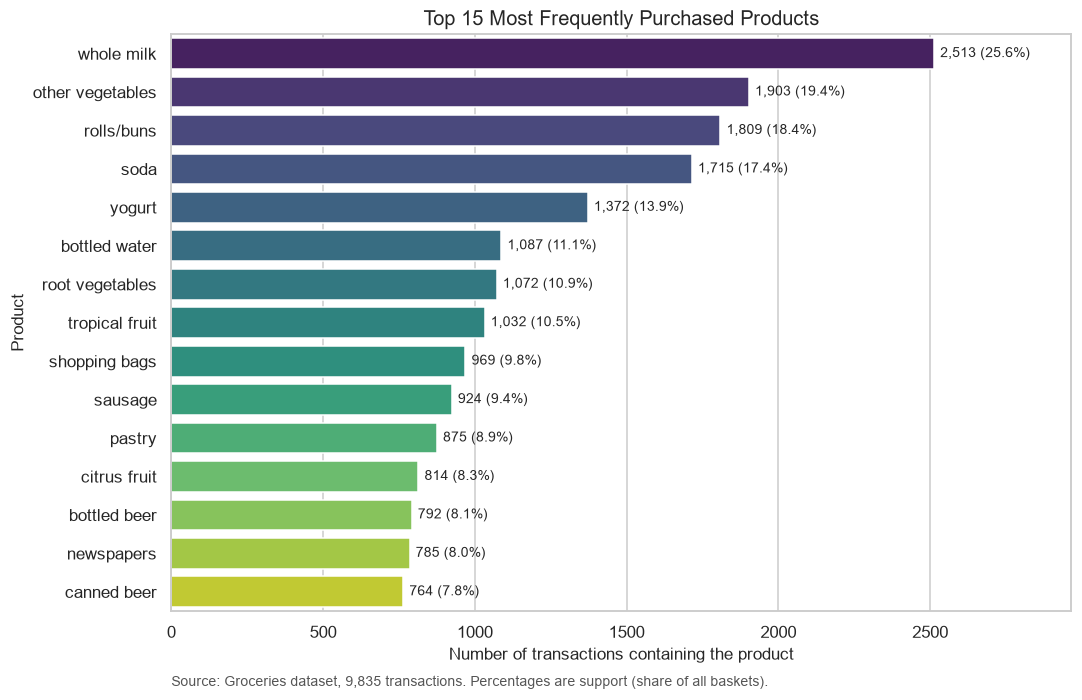

In [6]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.barplot(
    data=top_products,
    y="product",
    x="baskets",
    hue="product",
    palette="viridis",
    legend=False,
    ax=ax,
)
for i, row in top_products.reset_index(drop=True).iterrows():
    ax.text(row["baskets"] + 20, i, f"{row['baskets']:,} ({row['support_pct']:.1f}%)",
            va="center", fontsize=9)

ax.set_title("Top 15 Most Frequently Purchased Products")
ax.set_xlabel("Number of transactions containing the product")
ax.set_ylabel("Product")
ax.set_xlim(0, top_products["baskets"].max() * 1.18)
ax.text(0.0, -0.13, f"Source: Groceries dataset, {len(baskets):,} transactions. "
        "Percentages are support (share of all baskets).",
        transform=ax.transAxes, fontsize=9, color="#555555")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "02_top_products.png", bbox_inches="tight")
plt.show()

**Reading the chart.** Whole milk is the clear leader, followed by other vegetables, rolls/buns, soda, and
yogurt. These are high-support "traffic" products. A store can use them to draw customers through the
aisles, but high frequency alone does not tell us what to place next to what. For that we need pairs and
rules.

Notice also that some labels are broad categories (`other vegetables`, `root vegetables`, `tropical fruit`)
rather than individual SKUs. This is a property of the dataset and an important limitation.

## 6. Convert baskets to a one-hot table

Apriori needs a rectangular table:

- one row per transaction;
- one column per product;
- `True` if the product is in that basket, `False` otherwise.

`TransactionEncoder` from `mlxtend` performs this conversion. The result is **sparse** in nature: most
cells are `False`, because a basket contains only a few of the 169 products.

In [7]:
encoder = TransactionEncoder()
encoded_array = encoder.fit(baskets).transform(baskets)
onehot = pd.DataFrame(encoded_array, columns=encoder.columns_)

density = onehot.to_numpy().mean()
print(f"One-hot table shape: {onehot.shape[0]:,} rows x {onehot.shape[1]:,} product columns")
print(f"Density: {density:.2%} of cells are True (non-zero)")
print("\nFirst 5 transactions and first 8 products:")
display(onehot.iloc[:5, :8])

One-hot table shape: 9,835 rows x 169 product columns
Density: 2.61% of cells are True (non-zero)

First 5 transactions and first 8 products:


,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


**Why this matters.** A support count is now just a column sum. For product *X*, support is the number of
`True` values in column *X* divided by the number of rows. Apriori uses these sums to prune the search:
if a single product is not frequent enough, no larger set containing it can be frequent either.

## 7. Apriori: find frequent itemsets

### Choosing minimum support

**Support** is the fraction of all transactions that contain a set of products.

$$
\text{support}(A \cup B) = \frac{\text{number of baskets containing both } A \text{ and } B}{\text{total number of baskets}}
$$

A **minimum support** threshold removes rare combinations. We use:

- **Full Groceries dataset:** `min_support = 0.01` (1%). That means an itemset must appear in at least
  about 98 of the 9,835 baskets. This is a common starting point for this dataset: low enough to find
  useful pairs, high enough to avoid thousands of one-off combinations.
- **Built-in sample:** `min_support = 0.15` (15%), because the sample has only 40 baskets.

The threshold is a **business choice**, not a law of statistics. Lower it and you get more rules, including
rare and noisy ones; raise it and you keep only very common patterns.

### How Apriori works (in one paragraph)

Apriori builds itemsets one size at a time. It first counts all single products and keeps those above
minimum support. It then joins frequent singles into pairs, counts the pairs, and keeps the frequent ones.
Frequent pairs are joined into triples, and so on. At every step it uses the **Apriori principle**: if an
itemset is infrequent, every larger itemset that contains it must also be infrequent, so those candidates
can be skipped. This pruning is what makes the search practical.

In [8]:
# The threshold depends on which data source is active.
MIN_SUPPORT = 0.15 if USING_SAMPLE else 0.01
MIN_CONFIDENCE = 0.40
MIN_LIFT = 1.0

required_baskets = int(np.ceil(MIN_SUPPORT * len(baskets)))
print(f"Minimum support: {MIN_SUPPORT:.0%} -> an itemset needs at least {required_baskets} baskets")
print(f"Minimum confidence for rules: {MIN_CONFIDENCE:.0%}")
print(f"Minimum lift for rules: {MIN_LIFT}")

frequent_itemsets = apriori(onehot, min_support=MIN_SUPPORT, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets = frequent_itemsets.sort_values(
    ["support", "length"], ascending=[False, True]
).reset_index(drop=True)

print(f"\nFrequent itemsets found: {len(frequent_itemsets):,}")
print("\nCount by itemset size:")
display(frequent_itemsets["length"].value_counts().sort_index().rename("count").to_frame())

# Save a readable copy.
frequent_output = frequent_itemsets.copy()
frequent_output["items"] = frequent_output["itemsets"].apply(lambda s: ", ".join(sorted(s)))
frequent_output["support_pct"] = (100 * frequent_output["support"]).round(2)
frequent_output[["items", "length", "support", "support_pct"]].to_csv(
    RESULTS_DIR / "frequent_itemsets.csv", index=False
)

Minimum support: 1% -> an itemset needs at least 99 baskets
Minimum confidence for rules: 40%
Minimum lift for rules: 1.0

Frequent itemsets found: 333

Count by itemset size:


,count
length,
1,88
2,213
3,32


In [9]:
def itemset_text(items):
    # Turn a frozenset such as {'milk', 'bread'} into readable text.
    return ", ".join(sorted(items))


# Show multi-item itemsets: these are the actual "bought together" patterns.
multi_item = frequent_itemsets[frequent_itemsets["length"] >= 2].copy()
multi_item["items"] = multi_item["itemsets"].apply(itemset_text)
multi_item["support_pct"] = (100 * multi_item["support"]).round(2)

top_itemsets = multi_item.sort_values(["support", "length"], ascending=[False, True]).head(12)
display(top_itemsets[["items", "length", "support_pct"]])

print("\nThe most frequent single products (for comparison):")
single_item = frequent_itemsets[frequent_itemsets["length"] == 1].copy()
single_item["items"] = single_item["itemsets"].apply(itemset_text)
single_item["support_pct"] = (100 * single_item["support"]).round(2)
display(single_item.sort_values("support", ascending=False).head(10)[["items", "support_pct"]])

,items,length,support_pct
16,"other vegetables, whole milk",2,7.48
25,"rolls/buns, whole milk",2,5.66
26,"whole milk, yogurt",2,5.60
32,"root vegetables, whole milk",2,4.89
34,"other vegetables, root vegetables",2,4.74
35,"other vegetables, yogurt",2,4.34
37,"other vegetables, rolls/buns",2,4.26
38,"tropical fruit, whole milk",2,4.23
40,"soda, whole milk",2,4.01
43,"rolls/buns, soda",2,3.83



The most frequent single products (for comparison):


,items,support_pct
0,whole milk,25.55
1,other vegetables,19.35
2,rolls/buns,18.39
3,soda,17.44
4,yogurt,13.95
5,bottled water,11.05
6,root vegetables,10.90
7,tropical fruit,10.49
8,shopping bags,9.85
9,sausage,9.40


**What the itemset table shows.** Many of the strongest pairs involve vegetables and dairy. For example,
`root vegetables + other vegetables` and `whole milk + other vegetables` are frequent. These pairs are the
raw material for rules. On the full dataset, Apriori typically finds a few hundred frequent itemsets, and
no itemset with four or more products survives the 1% threshold (the exact count is printed above).

## 8. Generate and rank association rules

A frequent itemset is not yet a rule. From `{root vegetables, other vegetables}` we can form two rules:

- `root vegetables -> other vegetables`
- `other vegetables -> root vegetables`

They are not equally useful, because confidence is directional.

### Confidence and lift

$$
\text{confidence}(A \rightarrow B) = \frac{\text{support}(A \cup B)}{\text{support}(A)}
= P(B \mid A)
$$

Confidence answers: *among baskets containing A, what share also contain B?*

$$
\text{lift}(A \rightarrow B) = \frac{\text{confidence}(A \rightarrow B)}{\text{support}(B)}
= \frac{P(B \mid A)}{P(B)}
$$

Lift compares the rule with the baseline. If lift is 1, A and B appear together about as often as
independence would predict. If lift is 2, B is twice as likely when A is present. If lift is below 1, the
products avoid each other.

**Which rules do we keep?** We require confidence of at least **40%** and lift greater than **1**. Confidence
removes weak rules; lift removes rules that are only impressive because B is popular on its own. The
thresholds are stated in the previous cell and can be changed.

In [10]:
rules = association_rules(
    frequent_itemsets.drop(columns="length"),
    metric="confidence",
    min_threshold=MIN_CONFIDENCE,
)

# Keep only positive associations (lift > 1).
rules = rules[rules["lift"] > MIN_LIFT].copy()

rules["antecedent"] = rules["antecedents"].apply(itemset_text)
rules["consequent"] = rules["consequents"].apply(itemset_text)
rules["rule"] = rules["antecedent"] + " -> " + rules["consequent"]
rules["antecedent_length"] = rules["antecedents"].apply(len)
rules["support_pct"] = (100 * rules["support"]).round(2)
rules["confidence_pct"] = (100 * rules["confidence"]).round(2)
rules["lift"] = rules["lift"].round(2)
rules["leverage"] = rules["leverage"].round(4)
rules["conviction"] = rules["conviction"].round(2)

rules = rules.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)
rules.insert(0, "rank", rules.index + 1)

print(f"Rules after confidence >= {MIN_CONFIDENCE:.0%} and lift > {MIN_LIFT}: {len(rules):,}")
print("\nRules by number of products on the left-hand side:")
display(rules["antecedent_length"].value_counts().sort_index().rename("count").to_frame())

rules.to_csv(RESULTS_DIR / "association_rules.csv", index=False)

Rules after confidence >= 40% and lift > 1.0: 62

Rules by number of products on the left-hand side:


,count
antecedent_length,
1,25
2,37


In [11]:
# Top rules by lift: the strongest "surprise" associations.
top_by_lift = rules.sort_values(["lift", "confidence"], ascending=False).head(10)
display(top_by_lift[["rule", "support_pct", "confidence_pct", "lift"]])

print("\nTop rules by confidence: the most reliable directional rules.")
top_by_confidence = rules.sort_values(["confidence", "lift"], ascending=False).head(10)
display(top_by_confidence[["rule", "support_pct", "confidence_pct", "lift"]])

print("\nRules with the highest support: the most common patterns.")
top_by_support = rules.sort_values(["support", "lift"], ascending=False).head(10)
display(top_by_support[["rule", "support_pct", "confidence_pct", "lift"]])

,rule,support_pct,confidence_pct,lift
0,"citrus fruit, root vegetables -> other vegetables",1.04,58.62,3.03
1,"root vegetables, tropical fruit -> other veget...",1.23,58.45,3.02
2,"rolls/buns, root vegetables -> other vegetables",1.22,50.21,2.59
3,"root vegetables, yogurt -> other vegetables",1.29,50.00,2.58
4,"whipped/sour cream, yogurt -> other vegetables",1.02,49.02,2.53
5,"root vegetables, whole milk -> other vegetables",2.32,47.40,2.45
6,onions -> other vegetables,1.42,45.90,2.37
7,"pork, whole milk -> other vegetables",1.02,45.87,2.37
8,"whipped/sour cream, whole milk -> other vegeta...",1.46,45.43,2.35
9,"pip fruit, whole milk -> other vegetables",1.35,44.93,2.32



Top rules by confidence: the most reliable directional rules.


,rule,support_pct,confidence_pct,lift
0,"citrus fruit, root vegetables -> other vegetables",1.04,58.62,3.03
1,"root vegetables, tropical fruit -> other veget...",1.23,58.45,3.02
10,"curd, yogurt -> whole milk",1.01,58.24,2.28
12,"butter, other vegetables -> whole milk",1.15,57.36,2.24
13,"root vegetables, tropical fruit -> whole milk",1.20,57.00,2.23
15,"root vegetables, yogurt -> whole milk",1.45,56.30,2.20
17,"domestic eggs, other vegetables -> whole milk",1.23,55.25,2.16
24,"whipped/sour cream, yogurt -> whole milk",1.09,52.45,2.05
25,"rolls/buns, root vegetables -> whole milk",1.27,52.30,2.05
26,"other vegetables, pip fruit -> whole milk",1.35,51.75,2.03



Rules with the highest support: the most common patterns.


,rule,support_pct,confidence_pct,lift
61,yogurt -> whole milk,5.60,40.16,1.57
42,root vegetables -> whole milk,4.89,44.87,1.76
11,root vegetables -> other vegetables,4.74,43.47,2.25
59,tropical fruit -> whole milk,4.23,40.31,1.58
41,whipped/sour cream -> whole milk,3.22,44.96,1.76
36,domestic eggs -> whole milk,3.00,47.28,1.85
23,whipped/sour cream -> other vegetables,2.89,40.28,2.08
31,butter -> whole milk,2.76,49.72,1.95
32,curd -> whole milk,2.61,49.05,1.92
54,margarine -> whole milk,2.42,41.32,1.62


**How to read the rule tables.** A rule with support 1.04%, confidence 58.62%, and lift 3.03 means:

- 1.04% of **all** baskets contain both sides of the rule;
- 58.62% of baskets containing the left side also contain the right side;
- the right side is 3.03 times more likely than its normal baseline when the left side is present.

The strongest rules by lift tend to have low support, because they describe specific combinations. The
highest-support rules are usually simpler and involve popular products. A retailer needs both views:
high-support rules are easy to act on at scale, while high-lift rules can reveal useful niche bundles.

## 9. What support, confidence, and lift mean: a worked example

The next cell calculates the three metrics for the rule `root vegetables -> other vegetables` directly from
the data, without using mlxtend's output. This is a check that the definitions are clear and that the
library's numbers are correct.

In [12]:
item_a = "root vegetables"
item_b = "other vegetables"

count_a = sum(1 for basket in baskets if item_a in basket)
count_b = sum(1 for basket in baskets if item_b in basket)
count_ab = sum(1 for basket in baskets if item_a in basket and item_b in basket)

support_a = count_a / len(baskets)
support_b = count_b / len(baskets)
support_ab = count_ab / len(baskets)
confidence_ab = count_ab / count_a
lift_ab = confidence_ab / support_b

print(f"Transactions: {len(baskets):,}")
print(f"Containing {item_a}: {count_a:,} ({support_a:.2%})")
print(f"Containing {item_b}: {count_b:,} ({support_b:.2%})")
print(f"Containing both: {count_ab:,} ({support_ab:.2%})")
print()
print(f"Support({item_a} -> {item_b})    = {count_ab:,} / {len(baskets):,} = {support_ab:.2%}")
print(f"Confidence({item_a} -> {item_b}) = {count_ab:,} / {count_a:,} = {confidence_ab:.2%}")
print(f"Lift({item_a} -> {item_b})       = {confidence_ab:.2%} / {support_b:.2%} = {lift_ab:.2f}")
print()
print(
    f"Plain language: {confidence_ab:.1%} of baskets with {item_a} also contain {item_b}. "
    f"That is {lift_ab:.2f} times the normal rate of {support_b:.1%} for {item_b}."
)

Transactions: 9,835
Containing root vegetables: 1,072 (10.90%)
Containing other vegetables: 1,903 (19.35%)
Containing both: 466 (4.74%)

Support(root vegetables -> other vegetables)    = 466 / 9,835 = 4.74%
Confidence(root vegetables -> other vegetables) = 466 / 1,072 = 43.47%
Lift(root vegetables -> other vegetables)       = 43.47% / 19.35% = 2.25

Plain language: 43.5% of baskets with root vegetables also contain other vegetables. That is 2.25 times the normal rate of 19.3% for other vegetables.


### A simple non-technical analogy

Imagine 100 shopping baskets:

- 10 contain **root vegetables**;
- 20 contain **other vegetables**;
- 5 contain **both**.

Then support of the pair is 5/100 = **5%**. Among the 10 root-vegetable baskets, 5 also have other
vegetables, so confidence is 5/10 = **50%**. Because other vegetables already appear in 20% of all baskets,
the lift is 50% / 20% = **2.5**. The rule is not just common; it is 2.5 times more common than we would expect
if the two products were unrelated.

## 10. Visualisations

Three charts are required by the project brief:

1. A bar chart of the most frequently purchased products (already created in Section 5).
2. A scatter plot of support versus confidence, with lift shown by colour.
3. A bar chart of the strongest association rules by lift.

The next two cells create charts 2 and 3.

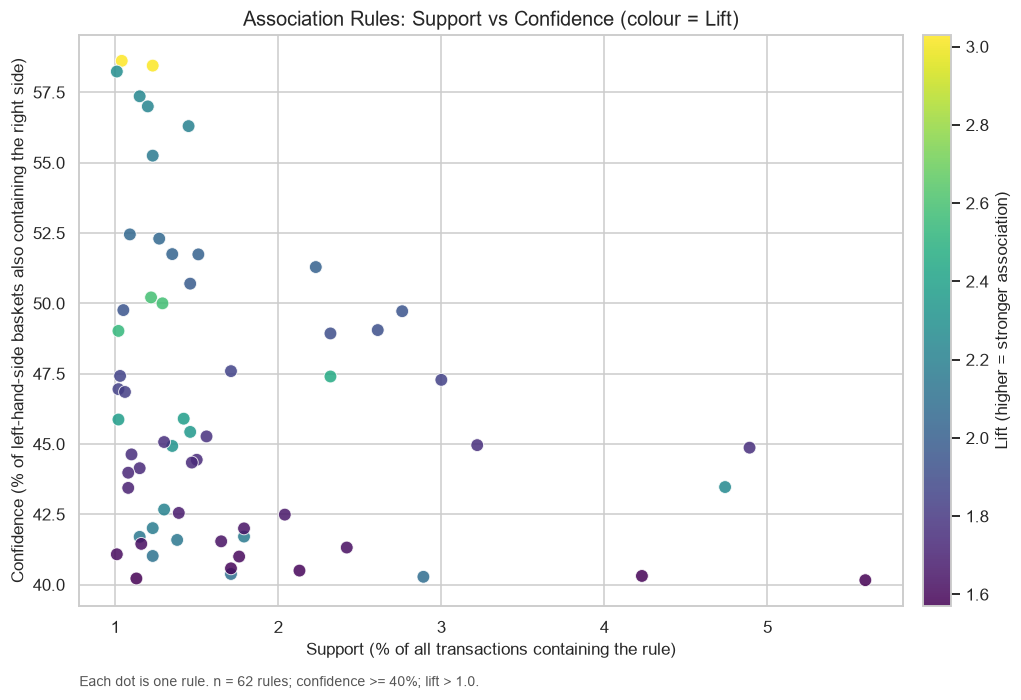

In [13]:
fig, ax = plt.subplots(figsize=(10, 6.5))
scatter = ax.scatter(
    rules["support_pct"],
    rules["confidence_pct"],
    c=rules["lift"],
    cmap="viridis",
    s=70,
    alpha=0.85,
    edgecolors="white",
    linewidths=0.6,
)
colorbar = fig.colorbar(scatter, ax=ax, pad=0.02)
colorbar.set_label("Lift (higher = stronger association)")

ax.set_title("Association Rules: Support vs Confidence (colour = Lift)")
ax.set_xlabel("Support (% of all transactions containing the rule)")
ax.set_ylabel("Confidence (% of left-hand-side baskets also containing the right side)")
ax.text(0.0, -0.14, f"Each dot is one rule. n = {len(rules):,} rules; "
        f"confidence >= {MIN_CONFIDENCE:.0%}; lift > {MIN_LIFT}.",
        transform=ax.transAxes, fontsize=9, color="#555555")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "03_support_confidence_lift.png", bbox_inches="tight")
plt.show()

**Reading the scatter plot.** Each dot is a rule. Moving right means the rule covers more transactions
(higher support). Moving up means the rule is more reliable when its left side occurs (higher confidence).
Colour shows lift: a bright dot is a stronger association than its baseline. The ideal rules sit toward the
top-right, but in real grocery data there is a trade-off — the very common rules rarely have the highest
lift. Look for bright dots in the upper-middle area, not just the far-right ones.

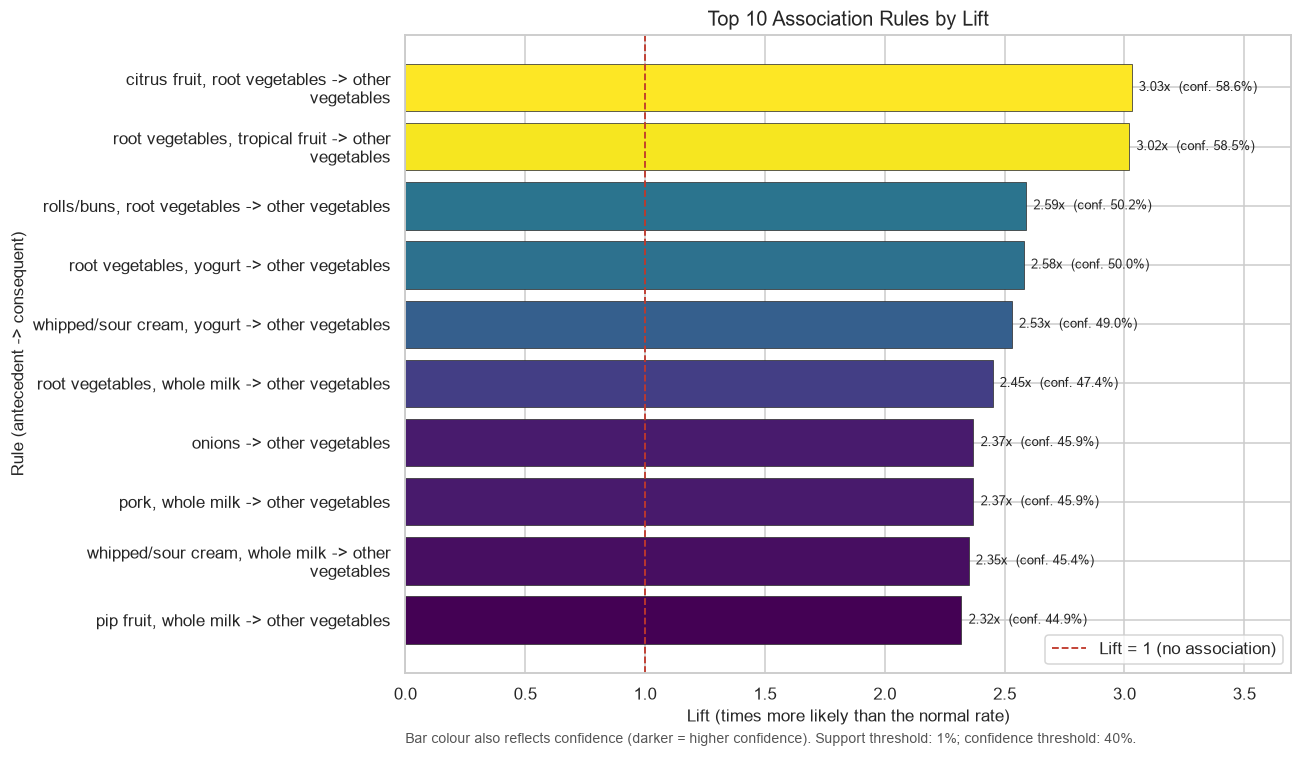

In [14]:
strongest = rules.sort_values(["lift", "confidence"], ascending=False).head(10).copy()
# Reverse so the strongest rule appears at the top of the horizontal chart.
strongest = strongest.iloc[::-1].reset_index(drop=True)

labels = [textwrap.fill(rule, width=48) for rule in strongest["rule"]]
norm = plt.Normalize(strongest["confidence_pct"].min(), strongest["confidence_pct"].max())
colors = plt.get_cmap("viridis")(norm(strongest["confidence_pct"]))

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(labels, strongest["lift"], color=colors, edgecolor="#333333", linewidth=0.5)
ax.axvline(1, color="#c0392b", linestyle="--", linewidth=1.2, label="Lift = 1 (no association)")

for bar, lift, conf in zip(bars, strongest["lift"], strongest["confidence_pct"]):
    ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height() / 2,
            f"{lift:.2f}x  (conf. {conf:.1f}%)", va="center", fontsize=8.5)

ax.set_title("Top 10 Association Rules by Lift")
ax.set_xlabel("Lift (times more likely than the normal rate)")
ax.set_ylabel("Rule (antecedent -> consequent)")
ax.set_xlim(0, strongest["lift"].max() * 1.22)
ax.legend(loc="lower right")
ax.text(0.0, -0.11, "Bar colour also reflects confidence (darker = higher confidence). "
        f"Support threshold: {MIN_SUPPORT:.0%}; confidence threshold: {MIN_CONFIDENCE:.0%}.",
        transform=ax.transAxes, fontsize=9, color="#555555")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "04_top_rules.png", bbox_inches="tight")
plt.show()

**Reading the rule chart.** The bars are the ten rules with the highest lift. Longer bars mean the
consequent is more strongly associated with the antecedent. The confidence printed at the end of each bar
tells us how often the rule is correct when its left side is present. A rule can be strong but rare (low
support), so always read lift together with support and confidence rather than ranking by one number only.

## 11. Interpretation and retail recommendations

The exact numbers below are produced by the cells above. They are not predictions and they are not proof
that one product causes another purchase. They are descriptions of co-occurrence in this dataset.

### What the analysis finds

On the full Groceries dataset (9,835 baskets, 169 products, 1% minimum support, 40% confidence, lift > 1):

- **Whole milk is the most common product**, appearing in about one in four baskets. Other vegetables,
  rolls/buns, soda, and yogurt are also very common. These are traffic-driving products.
- **The strongest rules are vegetable combinations.** Rules such as
  `{root vegetables, citrus fruit} -> other vegetables` and
  `{root vegetables, tropical fruit} -> other vegetables` have lift around **3.0**. In words, when those
  vegetables are already in the basket, other vegetables are about three times more likely than the
  baseline rate.
- **Dairy products reinforce each other.** Rules such as `{curd, yogurt} -> whole milk`,
  `butter -> whole milk`, and `{whipped/sour cream} -> whole milk` have lift around **1.8-2.3**. Customers
  buying one dairy item are more likely to buy milk as well.
- **Common rules are not always strong.** The highest-support rules (for example `yogurt -> whole milk`)
  cover more baskets but have lower lift than the specialised vegetable rules. This is the support-lift
  trade-off.

### How a store could use these patterns

1. **Product placement.** Keep complementary vegetables near each other, and place dairy items that go
   with milk within the same chilled aisle. Do not separate ingredients that frequently appear in the same
   basket.
2. **Bundles and meal ideas.** Create a "vegetable curry pack" (root vegetables, onions, other vegetables)
   or a "breakfast basket" (milk, yogurt, butter, eggs). The rules give evidence for which products belong
   together.
3. **Promotions.** Put the discount on the *less popular* complementary item rather than on milk, which
   already sells on its own. This can increase basket size without giving away margin on a traffic driver.
4. **Recommendations.** In an online store or app, when a basket contains root vegetables and citrus fruit,
   recommend other vegetables. The lift of about 3 means this is a much better recommendation than a random
   popular product.
5. **Shelf layout and store routing.** High-support products such as milk can be placed farther from the
   entrance so that customers pass other aisles. This is a hypothesis for testing, not a guaranteed effect.

### Important caution

Association rules describe **what happened together**, not **why**. Maybe customers plan a recipe; maybe a
promotion caused both purchases; maybe the categories are simply broad. A retailer should test a layout or
promotion change with a controlled experiment before rolling it out.

## 12. Limitations

1. **Old, context-free data.** The Groceries dataset is an older public snapshot. It has no dates, prices,
   quantities, customer IDs, store locations, or promotions. We cannot study seasonality, profit, or
   individual customer behaviour.
2. **Broad categories.** Labels such as `other vegetables` and `root vegetables` are categories, not
   individual products. A rule involving `other vegetables` is harder to action than a rule about a
   specific SKU.
3. **Support threshold is a choice.** A 1% threshold keeps patterns that occur at least about 98 times.
   Rare but profitable combinations are excluded. Lower thresholds produce many more rules, including
   noisy ones.
4. **Many rules, no significance test.** Apriori can generate many candidate rules. With 62 rules passing
   the filters, some may be chance patterns. Confidence and lift are descriptive; they are not p-values.
5. **Association is not causation.** Lift measures co-occurrence relative to baseline. It does not show
   that buying A makes a customer buy B, and it does not account for confounders such as promotions or
   recipe planning.
6. **Single-item baskets.** About 22% of baskets contain one item. They are valid transactions and are
   kept for correct support calculations, but they cannot contribute to any pair.
7. **Scalability.** Apriori is easy to understand but can become slow on very large catalogs because it
   generates candidate itemsets. This dataset is small enough to run quickly.
8. **No external validation.** The results are not tested on a second store, a newer period, or a holdout
   sample. They should not be generalised without checking.

## 13. Conclusion and future scope

This project shows a complete, reproducible market basket analysis workflow: load raw baskets, clean them,
one-hot encode, mine frequent itemsets with Apriori, generate rules with confidence and lift, visualise the
results, and translate them into retail actions. The main finding is that grocery baskets contain
meaningful structure: vegetables cluster with vegetables, dairy items cluster with milk, and some
combinations are around three times more likely than their baseline. At the same time, the analysis is
descriptive and the dataset is limited. Association rules are a starting point for business experiments,
not a substitute for them.

**Future improvements**

- Add prices and margins, then rank rules by expected profit rather than lift alone.
- Use a newer and larger transaction dataset with dates and customer IDs.
- Analyse seasonal patterns and compare rules across months or stores.
- Try FP-Growth, which avoids candidate generation and scales better.
- Add statistical significance or stability checks by bootstrapping baskets.
- Build a small recommendation demo that shows products for a sample basket.
- Test a proposed placement or bundle with an A/B experiment.

## 14. References

1. Agrawal, R., & Srikant, R. (1994). *Fast Algorithms for Mining Association Rules.* Proceedings of VLDB.
2. Tan, P.-N., Steinbach, M., & Kumar, V. *Introduction to Data Mining.* Pearson.
3. `mlxtend` documentation: <https://rasbt.github.io/mlxtend/>
4. Groceries dataset mirror:
   <https://github.com/stedy/Machine-Learning-with-R-datasets>
5. R `arules` package (original distribution of the Groceries data):
   <https://cran.r-project.org/package=arules>

## Reproducibility check

The final cell performs simple sanity checks and confirms that all output files were written. If any
assertion fails, the notebook will stop with an error instead of silently producing an incomplete project.

In [15]:
assert len(baskets) > 0, "No valid baskets were loaded."
assert unique_products > 0, "No products were found."
assert len(frequent_itemsets) > 0, "No frequent itemsets passed the support threshold."
assert len(rules) > 0, "No rules passed the confidence and lift thresholds."

expected_files = [
    RESULTS_DIR / "product_frequencies.csv",
    RESULTS_DIR / "frequent_itemsets.csv",
    RESULTS_DIR / "association_rules.csv",
    IMAGES_DIR / "01_basket_sizes.png",
    IMAGES_DIR / "02_top_products.png",
    IMAGES_DIR / "03_support_confidence_lift.png",
    IMAGES_DIR / "04_top_rules.png",
]
missing_files = [str(path) for path in expected_files if not path.exists()]
assert not missing_files, f"Missing output files: {missing_files}"

print("All checks passed.")
print(f"Data source: {'built-in sample' if USING_SAMPLE else 'data/groceries.csv'}")
print(f"Transactions analysed: {len(baskets):,}")
print(f"Distinct products: {unique_products}")
print(f"Frequent itemsets: {len(frequent_itemsets):,}")
print(f"Association rules: {len(rules):,}")
print("\nCharts saved in:", IMAGES_DIR)
print("Tables saved in:", RESULTS_DIR)

All checks passed.
Data source: data/groceries.csv
Transactions analysed: 9,835
Distinct products: 169
Frequent itemsets: 333
Association rules: 62

Charts saved in: C:\Users\SHINGADE27R\Documents\Default Project\market-basket-analysis\images
Tables saved in: C:\Users\SHINGADE27R\Documents\Default Project\market-basket-analysis\results
